# APIndex Sensitivity Analysis

## Purpose

This notebook validates the **Action Priority Index (APIndex)** across the three stakeholder perspectives:

- **Strategic**
- **Tactical**
- **Operational**

The analysis is separated into stages.  
**Part 1** examines the observed APIndex distributions and perspective-driven customer movement before defining any Low / Medium / High action-priority thresholds.

The thresholds are intentionally **not fixed in advance**. They should be supported by the observed model output rather than imposed arbitrarily.

> Source: APIndex outputs exported from Tableau for the three weighting profiles.


## APIndex Distribution & Threshold Assessment

### 1. Load Tableau model outputs

The Tableau CSV exports use UTF-16 encoding, tab separation, and a decimal comma.  
The helper function below reads this format and converts the APIndex to numeric values.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("processed_data")

FILES = {
    "Strategic": DATA_DIR / "api_strategic.csv",
    "Tactical": DATA_DIR / "api_tactical.csv",
    "Operational": DATA_DIR / "api_operational.csv",
}

def load_tableau_export(path, perspective):
    df = pd.read_csv(
        path,
        encoding="utf-16",
        sep="\t",
        decimal=","
    )

    df = df.rename(columns={
        "Customer Label": "customer",
        "APIndex Total": "apindex"
    })

    df["apindex"] = pd.to_numeric(df["apindex"], errors="coerce")
    df["perspective"] = perspective

    return df[["customer", "perspective", "apindex"]]

frames = [
    load_tableau_export(path, perspective)
    for perspective, path in FILES.items()
]

apindex_long = pd.concat(frames, ignore_index=True)

apindex_long.head()


,customer,perspective,apindex
0,C46,Strategic,0.688554
1,C45,Strategic,0.154639
2,C44,Strategic,0.485598
3,C43,Strategic,0.497562
4,C42,Strategic,0.539880


### 2. Completeness check

Before analysing the distributions, verify how many customers have a valid APIndex in each perspective.

Missing APIndex values are retained and documented rather than silently removed.  
A customer requires a complete KPI basis for the APIndex calculation.


In [2]:
completeness = (
    apindex_long
    .groupby("perspective")["apindex"]
    .agg(
        total_customers="size",
        valid_apindex="count"
    )
)

completeness["missing_apindex"] = (
    completeness["total_customers"] - completeness["valid_apindex"]
)

completeness


,total_customers,valid_apindex,missing_apindex
perspective,,,
Operational,46,40,6
Strategic,46,40,6
Tactical,46,40,6


In [3]:
missing_by_perspective = (
    apindex_long[apindex_long["apindex"].isna()]
    .groupby("perspective")["customer"]
    .apply(list)
)

missing_by_perspective


perspective
Operational    [C38, C36, C34, C26, C18, C05]
Strategic      [C38, C36, C34, C26, C18, C05]
Tactical       [C38, C36, C34, C26, C18, C05]
Name: customer, dtype: object

### 3. Create perspective comparison table

One row per customer makes it possible to compare the same customer across all three stakeholder perspectives.


In [4]:
apindex_wide = (
    apindex_long
    .pivot(index="customer", columns="perspective", values="apindex")
    .reset_index()
)

# Consistent column order
apindex_wide = apindex_wide[
    ["customer", "Strategic", "Tactical", "Operational"]
]

apindex_wide.head()


perspective,customer,Strategic,Tactical,Operational
0,C01,0.500175,0.201201,0.200494
1,C02,0.500026,0.200053,0.200026
2,C03,0.500000,0.200000,0.200000
3,C04,0.535541,0.271083,0.235541
4,C05,NaN,NaN,NaN


### 4. Descriptive statistics

The distributions are described independently for each perspective.

In addition to standard descriptive statistics, Q1, median and Q3 are shown explicitly because quartile-based thresholds are one possible candidate for Action Priority classification.


In [5]:
def distribution_summary(series):
    s = series.dropna()
    return pd.Series({
        "n": s.count(),
        "min": s.min(),
        "q1": s.quantile(0.25),
        "median": s.median(),
        "mean": s.mean(),
        "q3": s.quantile(0.75),
        "max": s.max(),
        "std": s.std()
    })

summary = (
    apindex_long
    .groupby("perspective")["apindex"]
    .apply(distribution_summary)
    .unstack()
    .reindex(["Strategic", "Tactical", "Operational"])
)

summary.round(4)


,n,min,q1,median,mean,q3,max,std
perspective,,,,,,,,
Strategic,40.0,0.0056,0.4960,0.5003,0.4757,0.5054,0.8003,0.1356
Tactical,40.0,0.0035,0.1997,0.2011,0.2153,0.2125,0.6007,0.1042
Operational,40.0,0.0027,0.1989,0.2005,0.2090,0.2060,0.8003,0.1128


### 5. Visualise the APIndex distributions

The same x-axis (0–1) is used for all perspectives so that differences in level and concentration remain directly comparable.

Separate plots are used intentionally rather than combining the distributions into a single chart.


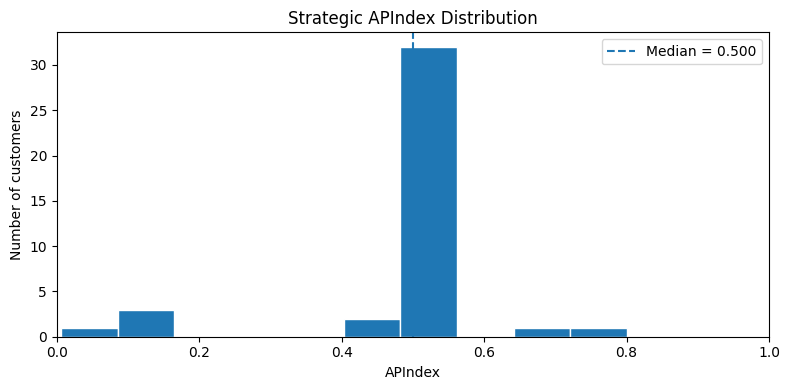

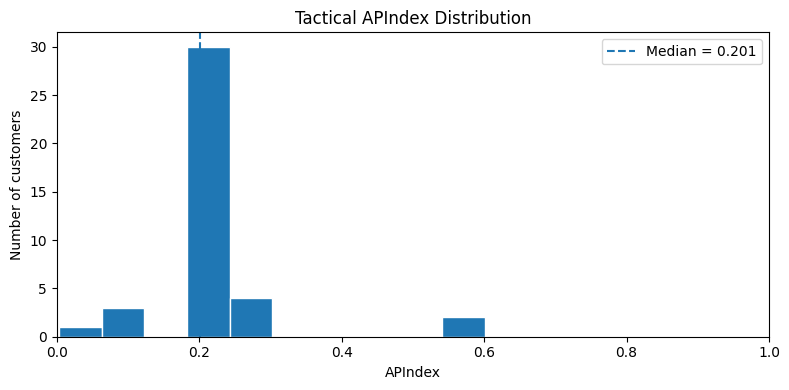

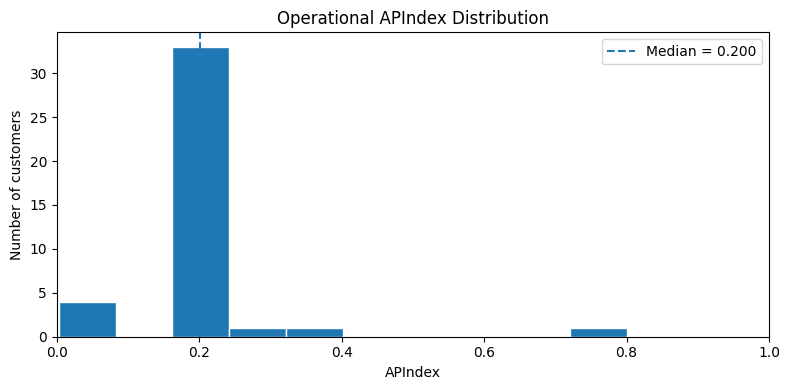

In [6]:
for perspective in ["Strategic", "Tactical", "Operational"]:
    values = apindex_long.loc[
        apindex_long["perspective"] == perspective,
        "apindex"
    ].dropna()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(values, bins=10, edgecolor="white")
    ax.axvline(values.median(), linestyle="--", linewidth=1.5, label=f"Median = {values.median():.3f}")
    ax.set_xlim(0, 1)
    ax.set_xlabel("APIndex")
    ax.set_ylabel("Number of customers")
    ax.set_title(f"{perspective} APIndex Distribution")
    ax.legend()
    plt.tight_layout()
    plt.show()


### 6. Perspective-driven customer movement

The KPI observations remain unchanged across perspectives.  
What changes is the **weighting profile**, and therefore the APIndex.

The following calculations quantify how much each customer's APIndex moves when the stakeholder perspective changes.


In [7]:
movement = apindex_wide.copy()

movement["Strategic_vs_Tactical"] = (
    movement["Strategic"] - movement["Tactical"]
)

movement["Strategic_vs_Operational"] = (
    movement["Strategic"] - movement["Operational"]
)

movement["Tactical_vs_Operational"] = (
    movement["Tactical"] - movement["Operational"]
)

movement["APIndex_range"] = (
    movement[["Strategic", "Tactical", "Operational"]]
    .max(axis=1)
    - movement[["Strategic", "Tactical", "Operational"]]
    .min(axis=1)
)

movement.sort_values("APIndex_range", ascending=False).head(10).round(4)


perspective,customer,Strategic,Tactical,Operational,Strategic_vs_Tactical,Strategic_vs_Operational,Tactical_vs_Operational,APIndex_range
1,C02,0.5000,0.2001,0.2000,0.3000,0.3,0.0000,0.3
38,C39,0.5426,0.2852,0.2426,0.2574,0.3,0.0426,0.3
21,C22,0.5165,0.2330,0.2165,0.2835,0.3,0.0165,0.3
20,C21,0.5008,0.2016,0.2008,0.2992,0.3,0.0008,0.3
19,C20,0.5024,0.2048,0.2024,0.2976,0.3,0.0024,0.3
6,C07,0.5069,0.2137,0.2069,0.2931,0.3,0.0069,0.3
7,C08,0.5004,0.2008,0.2004,0.2996,0.3,0.0004,0.3
41,C42,0.5399,0.2798,0.2399,0.2601,0.3,0.0399,0.3
9,C10,0.5004,0.2008,0.2004,0.2996,0.3,0.0004,0.3
10,C11,0.5008,0.2016,0.2008,0.2992,0.3,0.0008,0.3


### 7. Compare customer rankings across perspectives

A change in APIndex is relevant not only in absolute terms.  
It can also change the relative priority of a customer compared with the rest of the portfolio.

Rank 1 represents the highest APIndex within the respective perspective.


In [8]:
rankings = apindex_wide.copy()

for perspective in ["Strategic", "Tactical", "Operational"]:
    rankings[f"{perspective}_rank"] = (
        rankings[perspective]
        .rank(method="min", ascending=False)
    )

rankings[
    [
        "customer",
        "Strategic", "Strategic_rank",
        "Tactical", "Tactical_rank",
        "Operational", "Operational_rank"
    ]
].sort_values("Strategic_rank").head(15).round(4)


perspective,customer,Strategic,Strategic_rank,Tactical,Tactical_rank,Operational,Operational_rank
28,C29,0.8003,1.0,0.6007,1.0,0.8003,1.0
45,C46,0.6886,2.0,0.5954,2.0,0.3954,2.0
38,C39,0.5426,3.0,0.2852,3.0,0.2426,3.0
41,C42,0.5399,4.0,0.2798,4.0,0.2399,4.0
34,C35,0.5395,5.0,0.2791,5.0,0.2395,5.0
3,C04,0.5355,6.0,0.2711,6.0,0.2355,6.0
21,C22,0.5165,7.0,0.2330,7.0,0.2165,7.0
22,C23,0.5077,8.0,0.2155,9.0,0.2077,8.0
6,C07,0.5069,9.0,0.2137,10.0,0.2069,9.0
40,C41,0.5061,10.0,0.2121,11.0,0.2061,10.0


### 8. Threshold assessment — do not select thresholds yet

The goal is to create a **common Action Priority scale**:

- **Low**
- **Medium**
- **High**

Ideally, the same thresholds should apply to Strategic, Tactical and Operational views.  
This is important because a customer's Action Priority should be able to change as a consequence of the selected perspective — not because each perspective uses a different classification scale.

Before fixing thresholds, candidate cut-offs should be tested against the observed distributions and the resulting number of customers in each class.


In [10]:
def classify_priority(series, medium_threshold, high_threshold):
    return pd.cut(
        series,
        bins=[-np.inf, medium_threshold, high_threshold, np.inf],
        labels=["Low", "Medium", "High"],
        right=False
    )

def test_thresholds(medium_threshold, high_threshold):
    test = apindex_long.dropna(subset=["apindex"]).copy()
    test["action_priority"] = classify_priority(
        test["apindex"],
        medium_threshold,
        high_threshold
    )

    counts = (
        test.groupby(
            ["perspective", "action_priority"],
            observed=False
        )
        .size()
        .unstack(fill_value=0)
        .reindex(["Strategic", "Tactical", "Operational"])
    )

    return counts

# Example only — not a final threshold decision.
# Replace these values to inspect candidate classifications.
test_thresholds(
    medium_threshold=0.30,
    high_threshold=0.60
)
# Inspect customers behind the candidate Action Priority thresholds

threshold_check = apindex_long.dropna(subset=["apindex"]).copy()

threshold_check["action_priority"] = classify_priority(
    threshold_check["apindex"],
    medium_threshold=0.30,
    high_threshold=0.60
)

threshold_check = threshold_check.sort_values(
    ["perspective", "apindex"],
    ascending=[True, False]
)

threshold_check[
    threshold_check["action_priority"].isin(["Medium", "High"])
]

,customer,perspective,apindex,action_priority
109,C29,Operational,0.800344,High
92,C46,Operational,0.395422,Medium
17,C29,Strategic,0.800344,High
0,C46,Strategic,0.688554,High
7,C39,Strategic,0.542607,Medium
4,C42,Strategic,0.539880,Medium
11,C35,Strategic,0.539537,Medium
42,C04,Strategic,0.535541,Medium
24,C22,Strategic,0.516518,Medium
23,C23,Strategic,0.507726,Medium


### 9. Interpretation checkpoint

The candidate thresholds (Medium ≥ 0.30; High ≥ 0.60) produce a deliberately selective High-priority group. C29 remains High across all three perspectives, while C46 shifts from High in the Strategic view to Medium in Tactical and Operational views, demonstrating the intended perspective-dependent prioritization.

Because C46's Tactical APIndex (0.595) lies close to the candidate High threshold, the 0.60 cut-off is treated as provisional and will be evaluated in the subsequent sensitivity analysis (`05_APIndex_weight_sensitivity.ipynb`).
